In [1]:
pathfig = '/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/new_model_HNN/figures/'

import matplotlib.pyplot as plt
from alpha_beta_complex import (sim_analysis_params_default, run_alpha_beta_complex_simulations,
                                compute_psd, compute_tfr, compute_tfr_mne, alpha_beta_ratio, compute_symmetry_index)
import random
import pandas as pd
import os
import os.path as op
import numpy as np
import pickle

from hnn_core import duecker_2025_ET_model, simulate_dipole

main_pth = '/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/new_model_HNN/alpha_beta/'
out_pth = op.join(main_pth, 'sim_results')
path_fig = op.join(out_pth, 'figures')
os.makedirs(out_pth, exist_ok=True)
os.makedirs(path_fig, exist_ok=True)

n_procs = 10

import time


In [2]:
params = sim_analysis_params_default()
params['n_procs'] = n_procs

In [3]:
t = time.time()
dpl, net = run_alpha_beta_complex_simulations(params)
elapsed = time.time() - t

MPI will run 1 trial(s) sequentially by distributing network neurons over 10 processes.
numprocs=10
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Building the NEURON model
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Load

(0.0, 50.0)

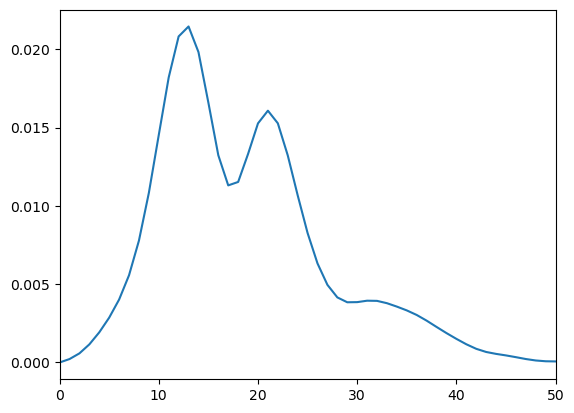

In [4]:
f, psd = compute_psd(params, dpl)
plt.plot(f, psd)
plt.xlim([0, 50])

In [5]:
# from scipy import signal
# frequencies = np.arange(1, 40, 1)  # frequencies
# m = 7                               # number of cycles

# sigma_t = m/(2*np.pi*frequencies)
# A = 1/(sigma_t*np.sqrt(2*np.pi))        # normalization factor

# # create wavelets
# wavelets = []
# for fi, f in enumerate(frequencies):

#     # timevec is different for each frequency
#     timevec = np.arange(0.0, 7.0*sigma_t[fi], 1/dpl.sfreq)
#     # row wise merging (np.r_) -> real and imaginary part of the wavelet are symmetric (without this, we only get half a wavelet)
#     timevec = np.r_[-timevec[::-1], timevec[1:]]
#     oscillation = np.exp(2*1j*np.pi*f*timevec)
#     gaussian_envelope = np.exp(-(timevec**2)/(2*sigma_t[fi]**2))
#     # create wavelet based on formula in Jones 2009
#     wavelets.append(A[fi]*oscillation*gaussian_envelope)

# # # convolve wavelets with signal
# tfr = np.zeros((len(frequencies), len(dpl.data['agg'])))
# for fi, f in enumerate(frequencies):
#     convolved = signal.convolve(dpl.data['agg'], wavelets[fi], mode='full')
#     start = wavelets[fi].size // 2
#     end = len(convolved) - (wavelets[fi].size // 2)
#     # take the middle values
#     tfr[fi, :] = np.abs(convolved[start:end])**2

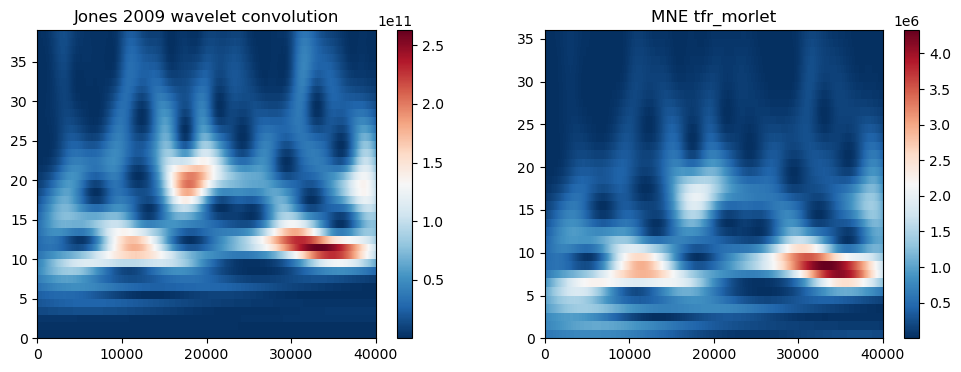

In [5]:
frequencies, tfr = compute_tfr(dpl)
frequencies, times, power, pad_dpl = compute_tfr_mne(dpl)
idx = (times >= 0) & (times <= 1001)
power = power[:, idx]

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
im = ax[0].pcolormesh(tfr, cmap='RdBu_r')
ax[0].set_title('Jones 2009 wavelet convolution')
plt.colorbar(im, ax=ax[0])
im = ax[1].pcolormesh(power, cmap='RdBu_r')
ax[1].set_title('MNE tfr_morlet')
plt.colorbar(im, ax=ax[1])

fig.savefig(op.join(pathfig, 'tfr_comparison.png'), dpi=300)


In [6]:
ab_ratio, a, b = alpha_beta_ratio(dpl)

In [7]:
# delay ratio
delays = np.arange(0, 95, 30)
ab_ratio = np.zeros_like(delays, dtype=float)
for i, delay in enumerate(delays):
    params = sim_analysis_params_default()
    params['fb_delay'] = delay
    params['n_procs'] = n_procs
    dpl, _ = run_alpha_beta_complex_simulations(params)
    ratio, _, _ = alpha_beta_ratio(dpl)
    
    ab_ratio[i] = ratio.mean()

df_delay = pd.DataFrame(data={'fb_delay': delays, 'ab_ratio': ab_ratio})
df_delay.to_pickle(op.join(out_pth, 'ab_ratio_delay.pkl'))

MPI will run 1 trial(s) sequentially by distributing network neurons over 10 processes.
numprocs=10
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Building the NEURON model
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Load

/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/parallel_backends.py:211: UserWarning: Received KeyboardInterrupt. Stopping simulation process...
  warn("Received KeyboardInterrupt. Stopping simulation process...")


RuntimeError: MPI simulation failed. Return code: 1

In [ ]:
ratio.mean()

np.float64(4.674574145186932)

In [ ]:
# burst std ratio
burst_stds = np.arange(np.sqrt(200), np.sqrt(600), 4)
burst_ratio_prox = np.zeros_like(burst_stds, dtype=float)
burst_ratio_dist = np.zeros_like(burst_stds, dtype=float)

for i, bstd in enumerate(burst_stds):
    params = sim_analysis_params_default()
    params['burst_std_prox'] = bstd
    params['n_procs'] = n_procs
    dpl, _ = run_alpha_beta_complex_simulations(params)
    ab_ratio, _, _ = alpha_beta_ratio(dpl).mean()
    burst_ratio_prox[i] = ab_ratio.mean()

for i, bstd in enumerate(burst_stds):
    params = sim_analysis_params_default()
    params['burst_std_dist'] = bstd
    params['n_procs'] = n_procs
    dpl, _ = run_alpha_beta_complex_simulations(params)
    ab_ratio, _, _ = alpha_beta_ratio(dpl).mean()
    burst_ratio_dist[i] = ab_ratio.mean()

df_burst = pd.DataFrame(data={'burst_std_prox': burst_stds, 'ab_ratio_prox': burst_ratio_prox, 'ab_ratio_dist': burst_ratio_dist})
df_burst.to_pickle(op.join(out_pth, 'ab_ratio_burst.pkl'))

In [ ]:
# N drive cells
num_cells = np.arange(5, 15, 5)
num_ratio_prox = np.zeros_like(num_cells, dtype=float)
num_ratio_dist = np.zeros_like(num_cells, dtype=float)

for n, n_cells in enumerate(num_cells):
    params = sim_analysis_params_default()
    params['n_drive_cells_prox'] = n_cells
    params['n_procs'] = n_procs
    dpl, _ = run_alpha_beta_complex_simulations(params)
    ab_ratio, _, _ = alpha_beta_ratio(dpl).mean()
    num_ratio_prox[n] = ab_ratio.mean()

for n, n_cells in enumerate(num_cells):
    params = sim_analysis_params_default()
    params['n_drive_cells_dist'] = n_cells
    params['n_procs'] = n_procs
    dpl, _ = run_alpha_beta_complex_simulations(params)
    ab_ratio, _, _ = alpha_beta_ratio(dpl).mean()
    num_ratio_dist[n] = ab_ratio.mean()

df_ncells = pd.DataFrame(data={'n_drive_cells': num_cells, 'ab_ratio_prox': num_ratio_prox, 'ab_ratio_dist': num_ratio_dist})
df_ncells.to_pickle(op.join(out_pth, 'ab_ratio_ncells.pkl'))

In [ ]:
# AMPA weights ratio
ampa_weights = np.linspace(0.00002, 0.00006, 3)
ampa_ratio_prox = np.zeros_like(ampa_weights, dtype=float)
ampa_ratio_dist = np.zeros_like(ampa_weights, dtype=float)

for a, w in enumerate(ampa_weights):
    params = sim_analysis_params_default()
    params['weights_ampa_p'] = {'L2_basket': 0.0, 'L2_pyramidal': w, 'L5_pyramidal': w, 'L5_basket': 0.0} # proximal weights
    params['n_procs'] = n_procs
    dpl, _ = run_alpha_beta_complex_simulations(params)
    ab_ratio, _, _ = alpha_beta_ratio(dpl).mean()
    ampa_ratio_prox[a] = ab_ratio.mean()

for a, w in enumerate(ampa_weights):
    params = sim_analysis_params_default()
    params['weights_ampa_d'] = {'L2_basket': 0.0, 'L2_pyramidal': w, 'L5_pyramidal': w, 'L5_basket': 0.0} # distal weights
    params['n_procs'] = n_procs
    dpl, _ = run_alpha_beta_complex_simulations(params)
    ab_ratio, _, _ = alpha_beta_ratio(dpl).mean()
    ampa_ratio_dist[a] = ab_ratio.mean()


In [ ]:
0.00004

4e-05

In [ ]:
# Develop python script
# seeed_ja = 42
# job_id = 0
# random.seed(seeed_ja)

# filename = op.join(out_pth, f'alpha_beta_complex_simulation_job{job_id}_seed{seeed_ja}.pkl')
# df_dict = dict()
# df_dict['trial'] = []

# df_dict['seed_prox'] = []
# df_dict['seed_dist'] = []
# df_dict['alpha_power'] = []
# df_dict['beta_power'] = []
# df_dict['alpha_beta_ratio'] = []
# df_dict['symmetry_index'] = []
# for n in range(2):

#     df_dict['trial'].append(n)
#     params = sim_analysis_params_default()
#     params['prox_seed'] = random.randint(0,10000)
#     params['dist_seed'] = random.randint(0,10000)
#     df_dict['seed_prox'].append(params['prox_seed'])
#     df_dict['seed_dist'].append(params['dist_seed'])

#     dpl, net = run_alpha_beta_complex_simulations(params)

#     frequencies, times, power, pad_dpl = compute_tfr(dpl)
#     ab_ratio, alpha_power, beta_power = alpha_beta_ratio(frequencies, times, power, dpl.sfreq)
#     s_idx, (filt_dpl, peaks, troughs) = compute_symmetry_index(dpl, lowcut=7, highcut=29)

#     df_dict['alpha_beta_ratio'].append(ab_ratio)
#     df_dict['alpha_power'].append(alpha_power)
#     df_dict['beta_power'].append(beta_power)
#     df_dict['symmetry_index'].append(s_idx)

# df = pd.DataFrame(df_dict)
# df.to_pickle(filename)


MPI will run 1 trial(s) sequentially by distributing network neurons over 10 processes.
numprocs=10
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Loading custom mechanism files